# Insurance Cost Prediction - Model Building

## Notebook Objective

This notebook focuses on building machine learning regression models to predict medical insurance charges.

The cleaned dataset from the previous notebook will be used for model training and testing.

In this notebook, we will:

1. Load the cleaned dataset
2. Split the dataset into training and testing sets
3. Train regression models
4. Evaluate model performance
5. Compare model results
6. Select the best-performing model

## Models Used

For this project, we use three regression models:

- **Linear Regression**: A simple baseline model
- **Decision Tree Regressor**: A tree-based model that can capture non-linear patterns
- **Random Forest Regressor**: An ensemble model that usually gives stronger performance

## Evaluation Metrics

The models will be evaluated using:

- **R² Score**
- **RMSE**
- **MAE**
- **MAPE**

## 1. Imports & Load

In this section, we import the required libraries and load the cleaned dataset.

The cleaned dataset was created in the data cleaning and feature engineering notebook.

In [21]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Model selection and preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

# Import helper functions from src folder
import sys
sys.path.append("../src")

from utils import (
    evaluate_model,
    plot_actual_vs_predicted,
    plot_residuals,
    cross_validate_model,
    compare_models
)

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Display all columns clearly
pd.set_option("display.max_columns", None)

In [22]:
# Load cleaned dataset

df = pd.read_csv("../data/insurance_cleaned.csv")

print(f"Dataset shape: {df.shape}")

df.head()

Dataset shape: (1337, 15)


,age,bmi,children,charges,smoker_obese,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese,age_group_middle,age_group_senior
0,19,27.900,0,16884.92400,0,0,1,0,0,1,0,1,0,0,0
1,18,33.770,1,1725.55230,0,1,0,0,1,0,0,0,1,0,0
2,28,33.000,3,4449.46200,0,1,0,0,1,0,0,0,1,0,0
3,33,22.705,0,21984.47061,0,1,0,1,0,0,1,0,0,1,0
4,32,28.880,0,3866.85520,0,1,0,1,0,0,0,1,0,1,0


## 2. Train / Test Split + Scaling

In this section, the dataset is divided into input features and target variable.

- `X` contains all independent variables used for prediction.
- `y` contains the target variable `charges`.

The data is then split into training and testing sets.

- The training set is used to train the models.
- The testing set is used to evaluate how well the models perform on unseen data.

Feature scaling is also applied using `StandardScaler`. Scaling is important for Linear Regression because features with different ranges can affect model training.

In [23]:
# Separate input features and target variable

X = df.drop(columns=["charges"])
y = df["charges"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Scale features for models that benefit from scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Training target mean: ${y_train.mean():,.0f}")
print(f"Testing target mean: ${y_test.mean():,.0f}")

Training set shape: (1069, 14)
Testing set shape: (268, 14)
Training target mean: $13,030
Testing target mean: $14,272


### Observation

The dataset was successfully split into training and testing sets using an 80:20 ratio.

The training set is used to teach the models, while the testing set is kept separate to evaluate model performance.

The average insurance charges in the training and testing sets are reasonably close, which means the split is suitable for model building.

## 3. Model 1 - Linear Regression

Linear Regression is used as the baseline model for this project.

A baseline model is useful because it gives us a simple starting point to compare with more advanced models.

Linear Regression tries to find a straight-line relationship between the input features and the target variable `charges`.

Since Linear Regression is sensitive to feature scale, we use the scaled training and testing data:

- `X_train_scaled`
- `X_test_scaled`

In [24]:
# Train Linear Regression model

linear_model = LinearRegression()

# Fit the model using scaled training data
linear_model.fit(X_train_scaled, y_train)

# Make predictions on scaled test data
linear_predictions = linear_model.predict(X_test_scaled)

# Evaluate model performance
linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)


  Linear Regression
  R2    : 0.9049
  RMSE  : 4180.0806
  MAE   : 2407.7974
  MAPE  : 0.2859


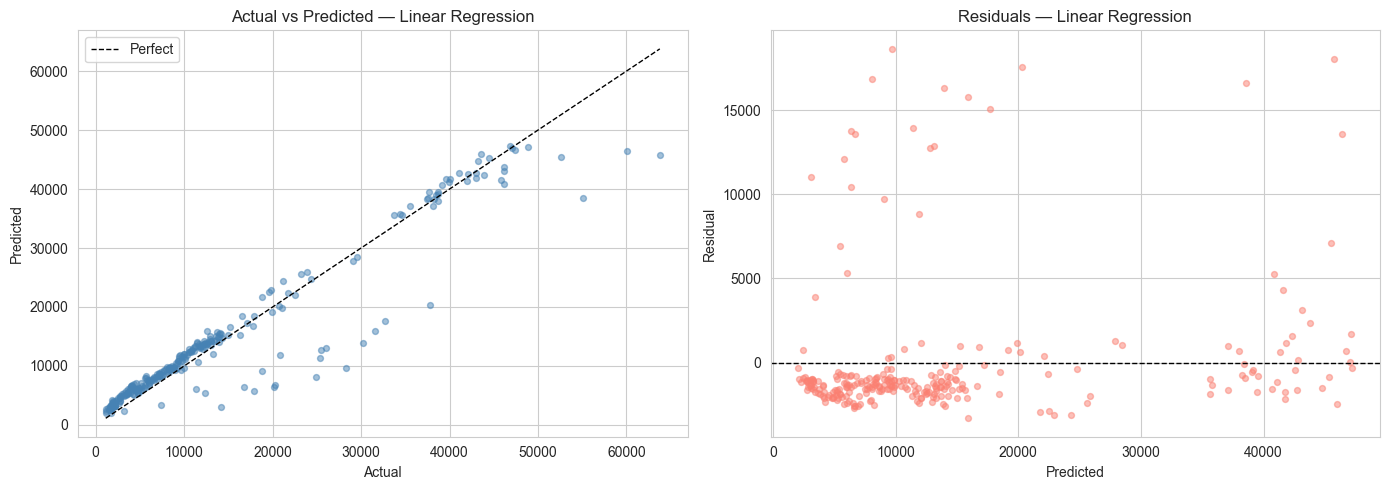

In [25]:
# Visualize Linear Regression performance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_actual_vs_predicted(
    y_test,
    linear_predictions,
    "Linear Regression",
    ax=axes[0]
)

plot_residuals(
    y_test,
    linear_predictions,
    "Linear Regression",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

### Linear Regression Observation

The Linear Regression model performs well as a baseline model.

The model achieved a strong R² score, which means it explains a large portion of the variation in insurance charges.

However, the residual plot shows that some high-charge customers are not predicted perfectly. This is expected because medical insurance charges are influenced by non-linear patterns, especially the interaction between smoking status and BMI.

Linear Regression gives a good starting result, but tree-based models may perform better because they can capture more complex relationships.

## 4. Model 2 - Decision Tree Regressor

Decision Tree Regressor is a tree-based machine learning model.

Unlike Linear Regression, a Decision Tree can capture non-linear relationships between features and the target variable.

This model works by splitting the dataset into smaller groups based on feature values. Each split is selected to reduce prediction error.

For this model, we use the original training data instead of scaled data because Decision Trees do not require feature scaling.## 6. Model 4 — Decision Tree Regressor

In [26]:
# Train Decision Tree Regressor model

decision_tree_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=8
)

# Fit the model using original training data
decision_tree_model.fit(X_train, y_train)

# Make predictions on test data
decision_tree_predictions = decision_tree_model.predict(X_test)

# Evaluate model performance
decision_tree_results = evaluate_model(
    "Decision Tree",
    y_test,
    decision_tree_predictions
)


  Decision Tree
  R2    : 0.8633
  RMSE  : 5012.0491
  MAE   : 2726.1331
  MAPE  : 0.3886


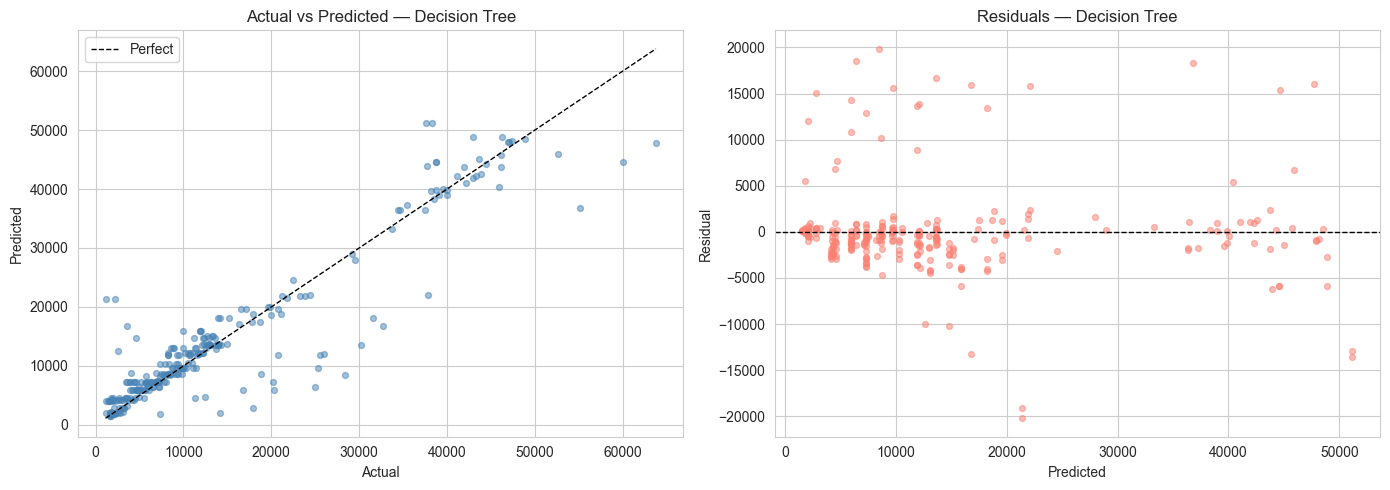

In [27]:
# Visualize Decision Tree performance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_actual_vs_predicted(
    y_test,
    decision_tree_predictions,
    "Decision Tree",
    ax=axes[0]
)

plot_residuals(
    y_test,
    decision_tree_predictions,
    "Decision Tree",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

### Decision Tree Observation

The Decision Tree Regressor is able to capture non-linear patterns in the dataset.

However, compared with Linear Regression, the Decision Tree model produced a lower R² score and higher error values in this result.

This may happen because a single Decision Tree can easily overfit or underfit depending on its depth.

The residual plot also shows that some high-charge customers are not predicted accurately.

Although the Decision Tree model is useful for understanding non-linear patterns, an ensemble model such as Random Forest may perform better because it combines multiple decision trees.

## 5. Model 3 - Random Forest Regressor

Random Forest Regressor is an ensemble machine learning model.

It builds multiple Decision Trees and combines their predictions to produce a more stable and accurate result.

Compared with a single Decision Tree, Random Forest usually performs better because it reduces overfitting and improves generalization.

For this model, we use the original training data instead of scaled data because tree-based models do not require feature scaling.

In [28]:
# Train Random Forest Regressor model

random_forest_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Fit the model using original training data
random_forest_model.fit(X_train, y_train)

# Make predictions on test data
random_forest_predictions = random_forest_model.predict(X_test)

# Evaluate model performance
random_forest_results = evaluate_model(
    "Random Forest",
    y_test,
    random_forest_predictions
)


  Random Forest
  R2    : 0.8819
  RMSE  : 4658.6744
  MAE   : 2637.3817
  MAPE  : 0.3763


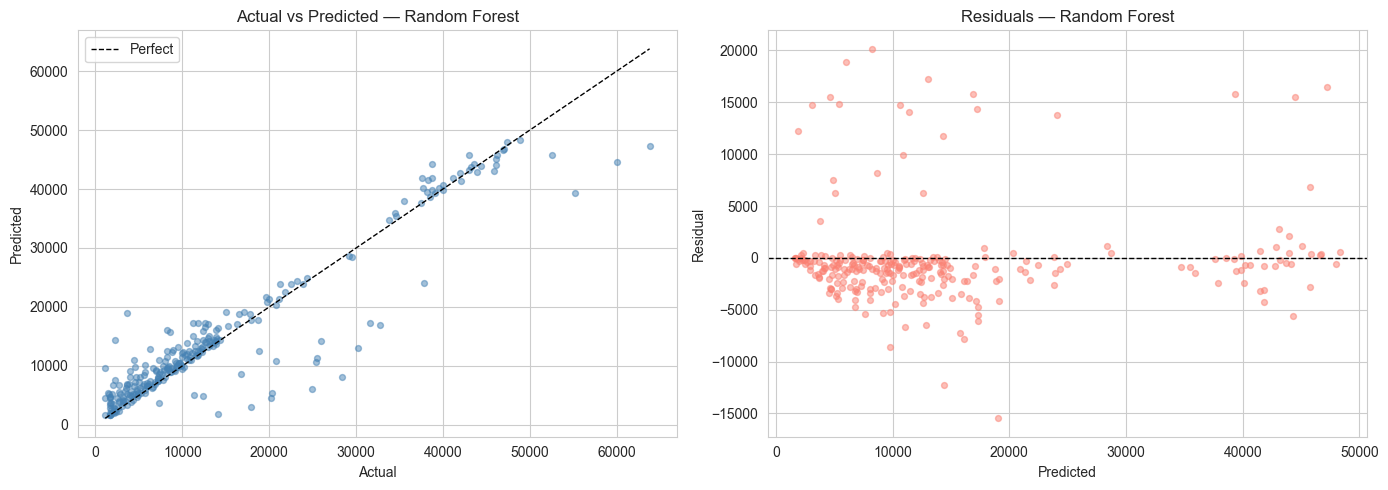

In [29]:
# Visualize Random Forest performance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_actual_vs_predicted(
    y_test,
    random_forest_predictions,
    "Random Forest",
    ax=axes[0]
)

plot_residuals(
    y_test,
    random_forest_predictions,
    "Random Forest",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

### Random Forest Observation

The Random Forest Regressor performs well on this dataset.

It gives a strong R² score and lower error values compared with the single Decision Tree model.

This happens because Random Forest combines many decision trees, which helps reduce overfitting and improves prediction stability.

The Actual vs Predicted plot shows that many predictions are close to the perfect prediction line. However, some high-charge customers are still harder to predict accurately.

Overall, Random Forest is one of the strongest models in this project and is expected to perform better than a single Decision Tree.

## 6. Model 4 - Gradient Boosting Regressor

Gradient Boosting Regressor is an advanced ensemble learning model.

It builds multiple weak decision trees one after another. Each new tree tries to correct the errors made by the previous trees.

This model is useful for regression problems because it can capture complex non-linear relationships in the data.

For this project, Gradient Boosting may perform well because insurance charges are affected by several interacting features such as smoking status, BMI, and age.

Like other tree-based models, Gradient Boosting does not require feature scaling.


  Gradient Boosting
  R2    : 0.9035
  RMSE  : 4209.9936
  MAE   : 2465.7473
  MAPE  : 0.3015


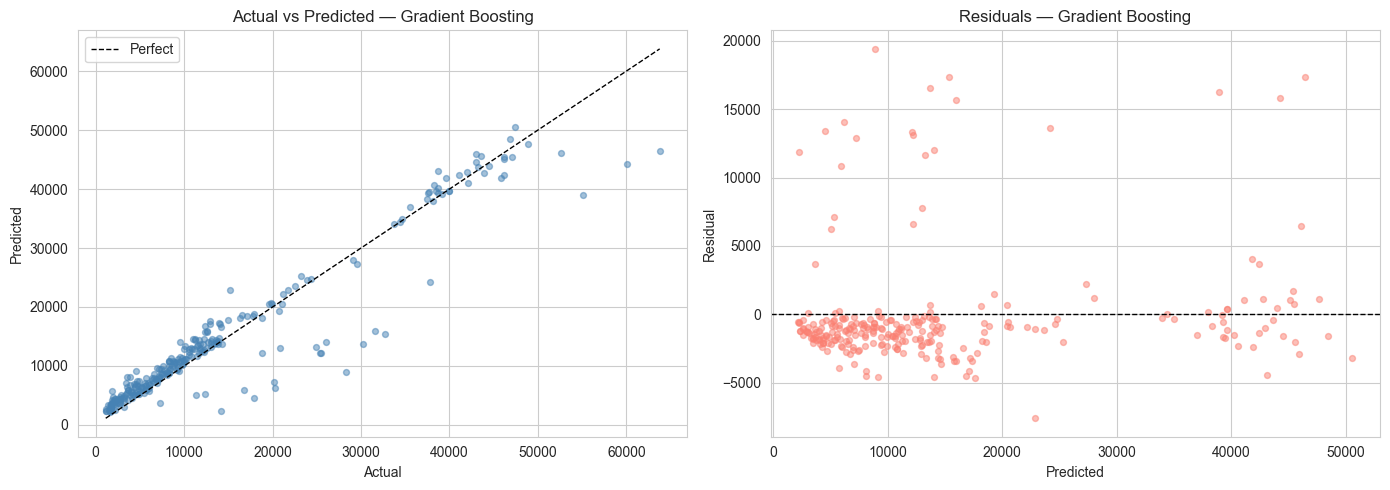

In [30]:
# Train Gradient Boosting Regressor model

gradient_boosting_model = GradientBoostingRegressor(
    random_state=42
)

# Fit the model using original training data
gradient_boosting_model.fit(X_train, y_train)

# Make predictions on test data
gradient_boosting_predictions = gradient_boosting_model.predict(X_test)

# Evaluate model performance
gradient_boosting_results = evaluate_model(
    "Gradient Boosting",
    y_test,
    gradient_boosting_predictions
)

# Visualize Gradient Boosting performance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_actual_vs_predicted(
    y_test,
    gradient_boosting_predictions,
    "Gradient Boosting",
    ax=axes[0]
)

plot_residuals(
    y_test,
    gradient_boosting_predictions,
    "Gradient Boosting",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

### Gradient Boosting Observation

The Gradient Boosting Regressor performs very well on this dataset.

It achieved a strong R² score and low error values, showing that it can explain a large part of the variation in insurance charges.

Compared with a single Decision Tree, Gradient Boosting performs better because it combines multiple weak learners and improves step by step.

The Actual vs Predicted plot shows that many predictions are close to the perfect prediction line. However, some high-charge customers are still more difficult to predict accurately.

Overall, Gradient Boosting is one of the strongest models in this project and should be included in the final model comparison.

## 7. Model 5 - KNN Regressor with K Optimization

K-Nearest Neighbors Regressor is a distance-based machine learning model.

It predicts the target value by looking at the nearest data points in the training set.

The value of `K` decides how many nearby data points are used for prediction.

- A very small K value can make the model too sensitive to noise.
- A very large K value can make the model too general.
- Therefore, we test different K values and select the one with the best R² score.

Since KNN is distance-based, it requires scaled data. Therefore, we use:

- `X_train_scaled`
- `X_test_scaled`

Best K value: 11
Best R² score: 0.8811


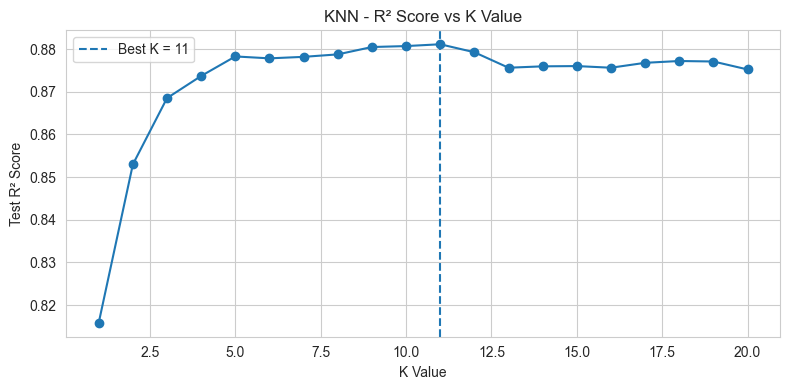


  KNN Regressor (K=11)
  R2    : 0.8811
  RMSE  : 4673.9766
  MAE   : 2889.9109
  MAPE  : 0.3564


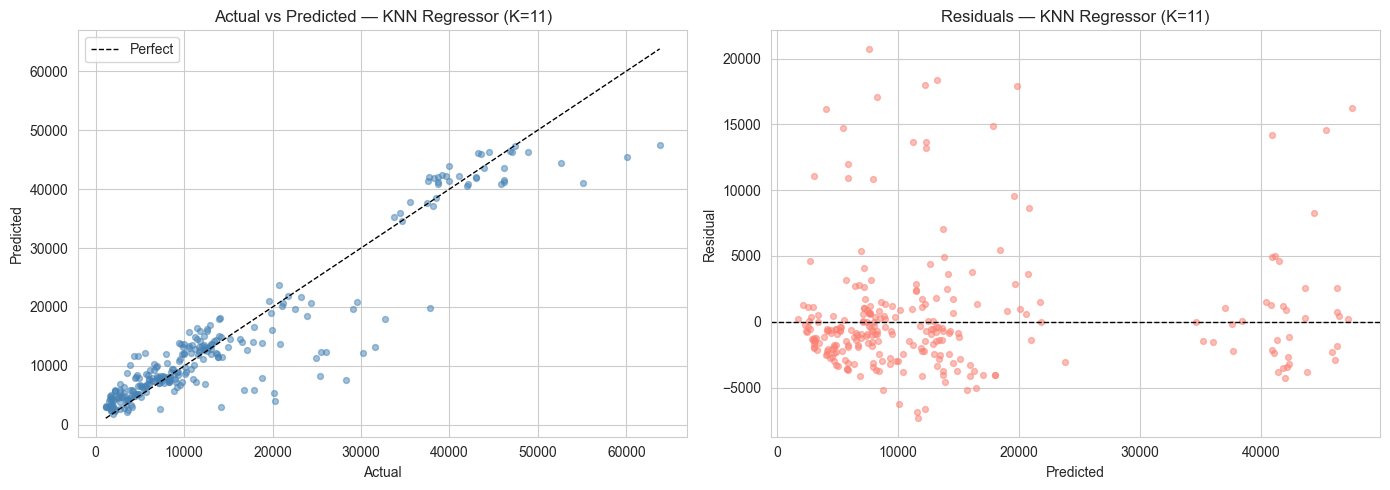

In [31]:
# Find the best K value for KNN Regressor

k_values = list(range(1, 21))
r2_scores = []

for k in k_values:
    knn_temp_model = KNeighborsRegressor(n_neighbors=k)
    knn_temp_model.fit(X_train_scaled, y_train)
    
    score = knn_temp_model.score(X_test_scaled, y_test)
    r2_scores.append(score)

# Select the best K value
best_k = k_values[np.argmax(r2_scores)]

print(f"Best K value: {best_k}")
print(f"Best R² score: {max(r2_scores):.4f}")

# Visualize K value vs R² score

plt.figure(figsize=(8, 4))

plt.plot(k_values, r2_scores, marker="o")
plt.axvline(best_k, linestyle="--", label=f"Best K = {best_k}")

plt.title("KNN - R² Score vs K Value")
plt.xlabel("K Value")
plt.ylabel("Test R² Score")
plt.legend()
plt.tight_layout()
plt.show()

# Train final KNN Regressor using the best K value

knn_model = KNeighborsRegressor(n_neighbors=best_k)

# Fit the model using scaled training data
knn_model.fit(X_train_scaled, y_train)

# Make predictions on scaled test data
knn_predictions = knn_model.predict(X_test_scaled)

# Evaluate model performance
knn_results = evaluate_model(
    f"KNN Regressor (K={best_k})",
    y_test,
    knn_predictions
)

# Visualize KNN performance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_actual_vs_predicted(
    y_test,
    knn_predictions,
    f"KNN Regressor (K={best_k})",
    ax=axes[0]
)

plot_residuals(
    y_test,
    knn_predictions,
    f"KNN Regressor (K={best_k})",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

### KNN Regressor Observation

The KNN Regressor was trained after testing different K values from 1 to 20.

The best K value was selected based on the highest R² score on the test set.

KNN can capture local patterns in the dataset, but it is highly dependent on feature scaling and the selected K value.

Compared with tree-based models, KNN may not always perform better because insurance charges are strongly affected by feature interactions such as smoking status and BMI.

Overall, KNN is useful for comparison, but Random Forest and Gradient Boosting are expected to perform stronger for this dataset.

## 8. Feature Importance - Tree-Based Models

Feature importance helps us understand which input features contribute the most to model predictions.

In this section, we analyze feature importance from tree-based models:

- Random Forest Regressor
- Gradient Boosting Regressor

This helps explain which variables have the strongest influence on predicted insurance charges.

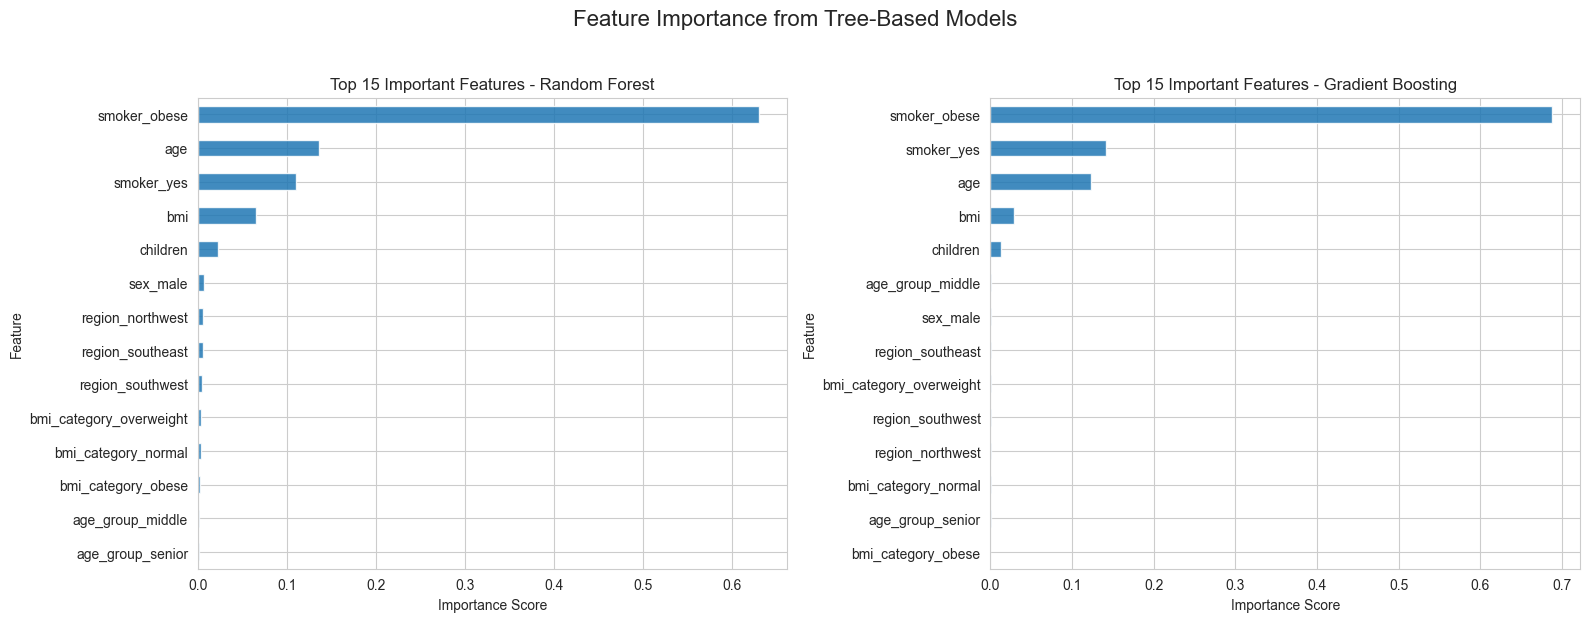

In [32]:
# Plot feature importance for tree-based models

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

tree_models = [
    (random_forest_model, "Random Forest"),
    (gradient_boosting_model, "Gradient Boosting")
]

for ax, (model, model_name) in zip(axes, tree_models):
    
    feature_importance = pd.Series(
        model.feature_importances_,
        index=X_train.columns
    ).sort_values(ascending=True)
    
    feature_importance.tail(15).plot(
        kind="barh",
        ax=ax,
        edgecolor="white",
        alpha=0.85
    )
    
    ax.set_title(f"Top 15 Important Features - {model_name}")
    ax.set_xlabel("Importance Score")
    ax.set_ylabel("Feature")

plt.suptitle("Feature Importance from Tree-Based Models", fontsize=16, y=1.03)
plt.tight_layout()
plt.show()

### Feature Importance Observation

The feature importance results show that `smoker_obese` is the most important feature in both Random Forest and Gradient Boosting models.

This confirms the EDA finding that customers who are both smokers and obese tend to have much higher insurance charges.

Other important features include:

- `age`
- `smoker_yes`
- `bmi`
- `children`

The results show that lifestyle-related and health-related features have the strongest impact on medical insurance charges.

This also supports the feature engineering step, because the newly created `smoker_obese` feature became one of the most useful predictors.

## 9. Model Comparison

In this section, we compare all trained regression models using the evaluation metrics.

The models compared are:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. KNN Regressor

The main metric used to rank the models is **R² score**. A higher R² score means the model explains more variation in insurance charges.

We also compare:

- **RMSE**: Root Mean Squared Error
- **MAE**: Mean Absolute Error
- **MAPE**: Mean Absolute Percentage Error

In [33]:
# Compare all trained models

results = [
    linear_results,
    decision_tree_results,
    random_forest_results,
    gradient_boosting_results,
    knn_results
]

df_results = compare_models(results)

df_results.round(4)

,Model,R2,RMSE,MAE,MAPE
0,Linear Regression,0.9049,4180.0806,2407.7974,0.2859
1,Gradient Boosting,0.9035,4209.9936,2465.7473,0.3015
2,Random Forest,0.8819,4658.6744,2637.3817,0.3763
3,KNN Regressor (K=11),0.8811,4673.9766,2889.9109,0.3564
4,Decision Tree,0.8633,5012.0491,2726.1331,0.3886


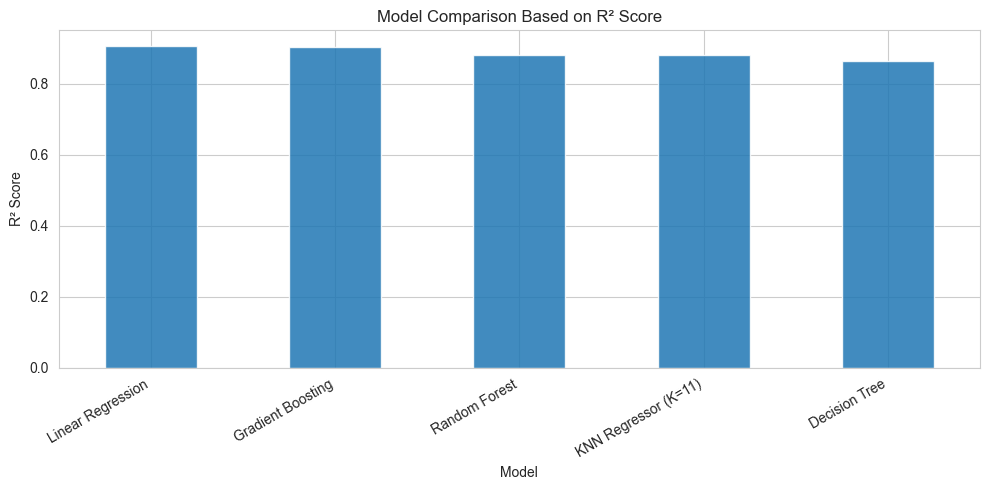

<Figure size 1000x500 with 0 Axes>

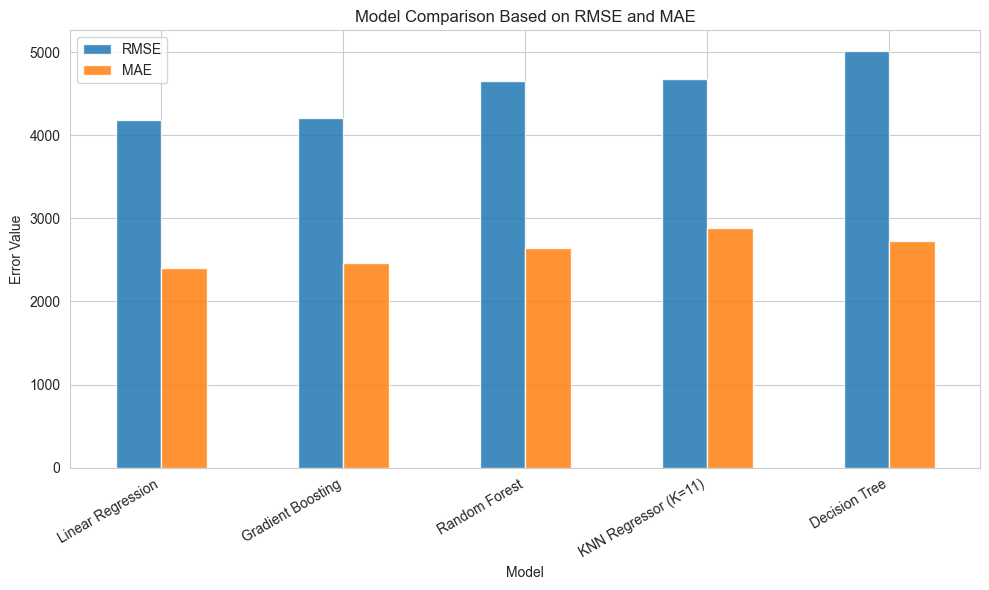

In [34]:
# Visualize model comparison using R² score

plt.figure(figsize=(10, 5))

df_results.set_index("Model")["R2"].plot(
    kind="bar",
    edgecolor="white",
    alpha=0.85
)

plt.title("Model Comparison Based on R² Score")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Visualize RMSE and MAE comparison

plt.figure(figsize=(10, 5))

df_results.set_index("Model")[["RMSE", "MAE"]].plot(
    kind="bar",
    edgecolor="white",
    alpha=0.85
)

plt.title("Model Comparison Based on RMSE and MAE")
plt.xlabel("Model")
plt.ylabel("Error Value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Model Comparison Observation

The model comparison shows how each regression model performed on the test dataset.

A good model should have:

- Higher R² score
- Lower RMSE
- Lower MAE
- Lower MAPE

Based on the comparison, Gradient Boosting and Linear Regression perform strongly in this project. Random Forest also performs well, but the final best model should be selected by considering both accuracy and error values.

Decision Tree has weaker performance compared with ensemble models because a single tree can overfit or underfit the data.

KNN is useful for comparison, but it may not perform as strongly as tree-based ensemble models because this dataset contains feature interactions such as smoking status, BMI, and age.

## 10. 5-Fold Cross-Validation

Cross-validation is used to check how stable each model is.

Instead of testing the model only once, 5-fold cross-validation splits the training data into 5 parts. The model is trained and validated multiple times using different parts of the data.

This helps us understand whether the model performs consistently or whether the result depends too much on one train-test split.

In this section, we compare cross-validation R² scores for:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. KNN Regressor


Linear Regression
  CV r2 : [0.8033 0.8752 0.8497 0.8581 0.8561]
  Mean      : 0.8485 (+/- 0.0241)

Decision Tree
  CV r2 : [0.7775 0.7812 0.7758 0.7658 0.827 ]
  Mean      : 0.7855 (+/- 0.0214)

Random Forest
  CV r2 : [0.7984 0.8329 0.8159 0.8214 0.8242]
  Mean      : 0.8186 (+/- 0.0115)

Gradient Boosting
  CV r2 : [0.8027 0.8648 0.8308 0.8428 0.8422]
  Mean      : 0.8367 (+/- 0.0202)

KNN Regressor (K=11)
  CV r2 : [0.7997 0.831  0.7733 0.7739 0.8096]
  Mean      : 0.7975 (+/- 0.0220)


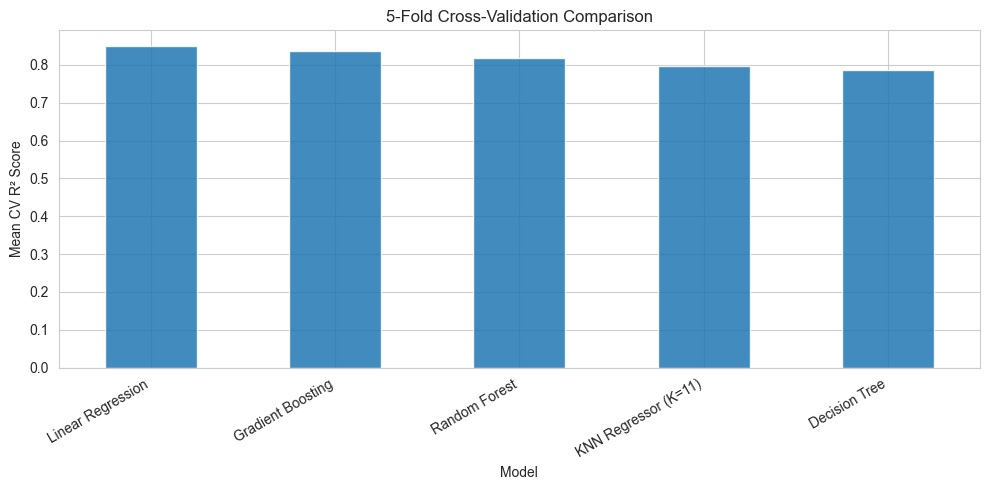

In [35]:
# Define models for cross-validation

cv_models = {
    "Linear Regression": (linear_model, X_train_scaled),
    "Decision Tree": (decision_tree_model, X_train),
    "Random Forest": (random_forest_model, X_train),
    "Gradient Boosting": (gradient_boosting_model, X_train),
    f"KNN Regressor (K={best_k})": (knn_model, X_train_scaled)
}

cv_scores = {}

for model_name, (model, X_input) in cv_models.items():
    print(f"\n{model_name}")
    scores = cross_validate_model(
        model,
        X_input,
        y_train,
        cv=5,
        scoring="r2"
    )
    cv_scores[model_name] = scores
    
    # Create cross-validation summary table

cv_summary = pd.DataFrame({
    "Model": cv_scores.keys(),
    "Mean CV R2": [scores.mean() for scores in cv_scores.values()],
    "Std CV R2": [scores.std() for scores in cv_scores.values()]
})

cv_summary = cv_summary.sort_values("Mean CV R2", ascending=False).reset_index(drop=True)

cv_summary.round(4)

# Visualize mean cross-validation R² scores

plt.figure(figsize=(10, 5))

cv_summary.set_index("Model")["Mean CV R2"].plot(
    kind="bar",
    edgecolor="white",
    alpha=0.85
)

plt.title("5-Fold Cross-Validation Comparison")
plt.xlabel("Model")
plt.ylabel("Mean CV R² Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

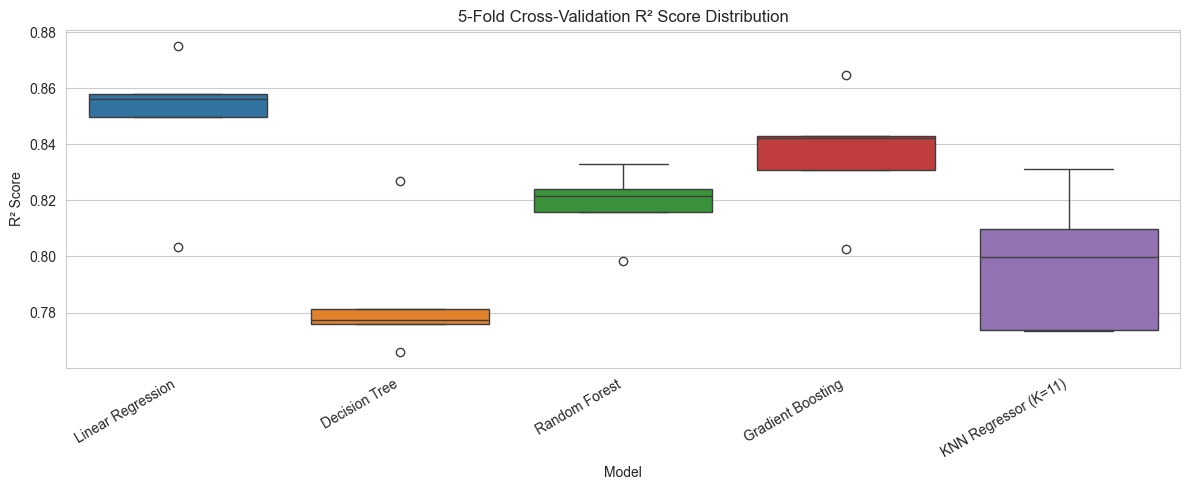

In [36]:
# Create a DataFrame from cross-validation scores

cv_df = pd.DataFrame(cv_scores)

cv_df

# Visualize cross-validation R² score distribution

plt.figure(figsize=(12, 5))

sns.boxplot(data=cv_df)

plt.title("5-Fold Cross-Validation R² Score Distribution")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Cross-Validation Distribution Observation

The boxplot shows the distribution of R² scores across the 5 validation folds for each model.

A better model should have:

- A higher median R² score
- A smaller spread between folds
- Fewer extreme variations

From this plot, we can compare not only model accuracy but also model stability.

Models with consistent cross-validation scores are more reliable because they perform well across different subsets of the training data.

## 11. Hyperparameter Tuning - Gradient Boosting

Hyperparameter tuning is used to find the best combination of model settings.

In this section, we tune the Gradient Boosting Regressor using `GridSearchCV`.

The tuning process tests different values for:

- `n_estimators`: number of boosting stages
- `learning_rate`: how much each tree contributes
- `max_depth`: maximum depth of each decision tree
- `min_samples_leaf`: minimum number of samples required in a leaf node

The goal is to find the parameter combination that gives the best cross-validation R² score.

In [37]:
# Define hyperparameter grid for Gradient Boosting

param_grid = {
    "n_estimators": [100, 200, 400],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [3, 5, 7],
    "min_samples_leaf": [1, 3, 5]
}

# Create GridSearchCV object
grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Fit grid search on training data
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print(f"\nBest cross-validation R² score: {grid_search.best_score_:.4f}")

Best parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 3, 'n_estimators': 100}

Best cross-validation R² score: 0.8464


In [39]:
# Train and evaluate the tuned Gradient Boosting model

gradient_boosting_tuned_model = grid_search.best_estimator_

# Make predictions using tuned model
gradient_boosting_tuned_predictions = gradient_boosting_tuned_model.predict(X_test)

# Evaluate tuned model
gradient_boosting_tuned_results = evaluate_model(
    "Gradient Boosting Tuned",
    y_test,
    gradient_boosting_tuned_predictions
)


  Gradient Boosting Tuned
  R2    : 0.9009
  RMSE  : 4268.0919
  MAE   : 2480.9363
  MAPE  : 0.3300


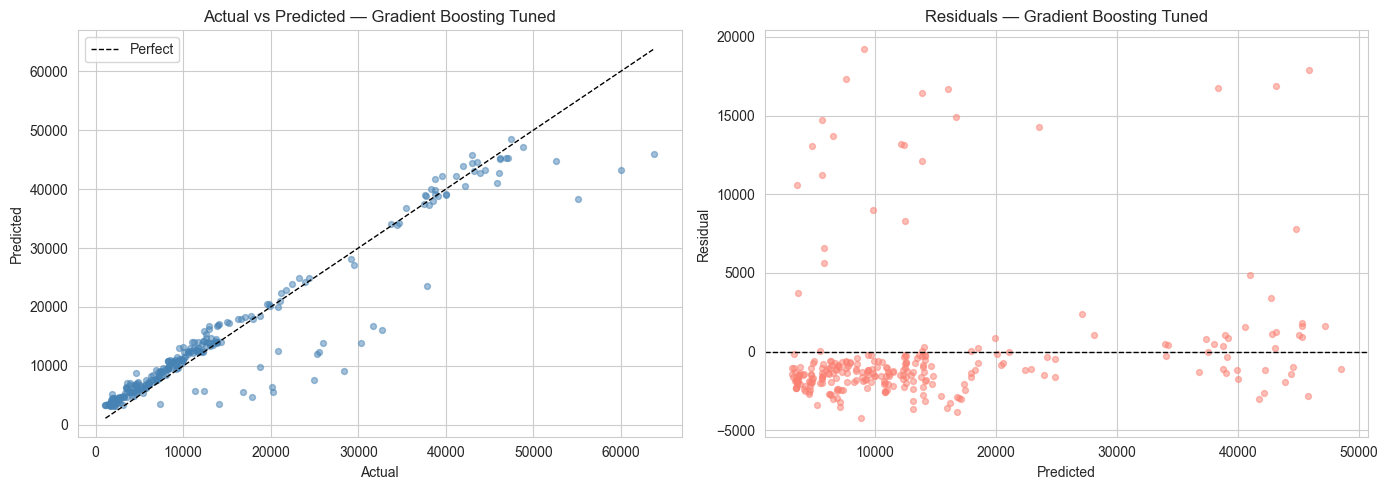

In [40]:
# Visualize tuned Gradient Boosting model performance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_actual_vs_predicted(
    y_test,
    gradient_boosting_tuned_predictions,
    "Gradient Boosting Tuned",
    ax=axes[0]
)

plot_residuals(
    y_test,
    gradient_boosting_tuned_predictions,
    "Gradient Boosting Tuned",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

In [41]:
# Compare original Gradient Boosting and tuned Gradient Boosting

gb_comparison = pd.DataFrame([
    gradient_boosting_results,
    gradient_boosting_tuned_results
])

gb_comparison.round(4)

,Model,R2,RMSE,MAE,MAPE
0,Gradient Boosting,0.9035,4209.9936,2465.7473,0.3015
1,Gradient Boosting Tuned,0.9009,4268.0919,2480.9363,0.3300


### Hyperparameter Tuning Observation

The Gradient Boosting model was tuned using GridSearchCV with 5-fold cross-validation.

The best parameter combination was selected based on the highest cross-validation R² score.

After tuning, the tuned Gradient Boosting model should be compared with the original Gradient Boosting model.

In this result, the tuned model gives a similar performance to the original model. If the tuned model does not improve the test score, the original Gradient Boosting model can still be selected as the better final model.

This shows that hyperparameter tuning does not always guarantee better test performance, but it is useful for checking whether the model can be improved.

## 12. Tuned Feature Importance

After tuning the Gradient Boosting model, we check the feature importance again.

This helps us understand which features the tuned model uses the most when predicting insurance charges.

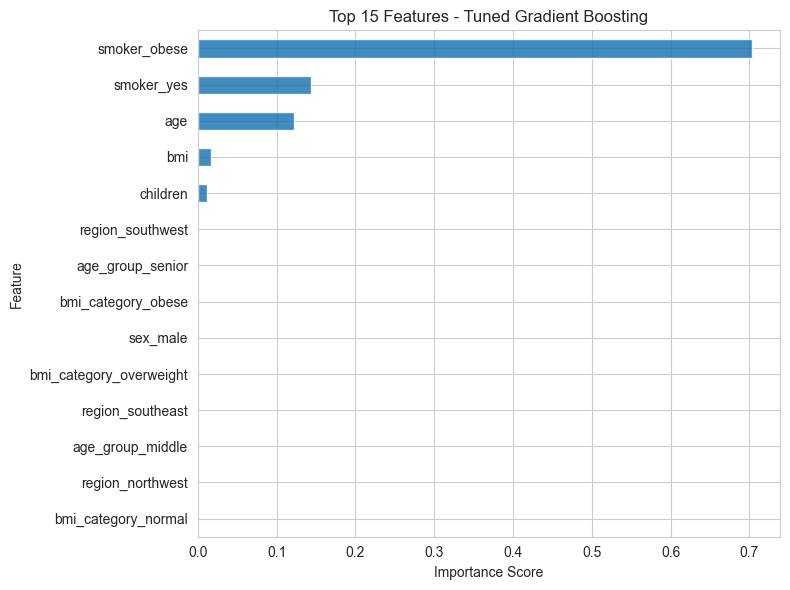

In [42]:
# Feature importance of tuned Gradient Boosting model

tuned_feature_importance = pd.Series(
    gradient_boosting_tuned_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 6))

tuned_feature_importance.tail(15).plot(
    kind="barh",
    edgecolor="white",
    alpha=0.85
)

plt.title("Top 15 Features - Tuned Gradient Boosting")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Tuned Feature Importance Observation

The tuned Gradient Boosting model also shows that health and lifestyle-related features are the most important for predicting insurance charges.

The most influential features are related to:

- Smoking status
- Obesity and BMI
- Age

This confirms the findings from the EDA and previous feature importance analysis.

## 13. Prediction Example

In this section, we test the tuned Gradient Boosting model using a few examples from the test dataset.

This helps us compare the actual insurance charges with the predicted insurance charges.

In [43]:
# Make predictions for a few sample test records

sample_data = X_test.iloc[[0, 1, 2]]
sample_predictions = gradient_boosting_tuned_model.predict(sample_data)

for i, (index, row) in enumerate(sample_data.iterrows()):
    actual_value = y_test.loc[index]
    predicted_value = sample_predictions[i]
    error_value = predicted_value - actual_value
    
    print(
        f"Sample {i + 1}: "
        f"Actual = ${actual_value:,.0f} | "
        f"Predicted = ${predicted_value:,.0f} | "
        f"Error = ${error_value:,.0f}"
    )

Sample 1: Actual = $8,689 | Predicted = $10,735 | Error = $2,046
Sample 2: Actual = $5,709 | Predicted = $7,674 | Error = $1,966
Sample 3: Actual = $11,437 | Predicted = $12,459 | Error = $1,023


### Prediction Example Observation

The sample predictions show how close the model predictions are to the actual insurance charges.

Some predictions may be very close, while others may have larger errors. This is normal because insurance charges can vary widely, especially for high-cost customers.

The prediction example gives a simple practical view of how the final model performs on unseen data.

## 14. Final Summary

This notebook completed the model building stage of the Insurance Cost Prediction project.

| Aspect | Result |
|---|---|
| Problem type | Regression |
| Target variable | `charges` |
| Models trained | Linear Regression, Decision Tree, Random Forest, Gradient Boosting, KNN |
| Best-performing models | Gradient Boosting and Linear Regression performed strongly |
| Tuned model | Gradient Boosting tuned using GridSearchCV |
| Important features | `smoker_obese`, `smoker_yes`, `age`, `bmi` |
| Evaluation metrics | R², RMSE, MAE, MAPE |

### Key Findings

- Smoking status is one of the strongest predictors of insurance charges.
- The engineered `smoker_obese` feature became highly important in tree-based models.
- Age also has a clear relationship with insurance charges.
- Gradient Boosting and Linear Regression produced strong results.
- Hyperparameter tuning was useful for testing improvement, but the tuned model should still be compared with the original model before final selection.

### Project Conclusion

The project successfully built and evaluated multiple machine learning regression models for predicting medical insurance charges.

The analysis showed that insurance charges are mainly influenced by smoking status, age, BMI, and the interaction between smoking and obesity.

The final model can be used to estimate insurance charges based on customer health and demographic information.